# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Andew Du, Rukaya Selim, Adeline Kwakye

**Date:** 11/16/2026

In [7]:
from google.colab import files
uploaded = files.upload()

Saving L03-tree-stability-main.zip to L03-tree-stability-main.zip


In [8]:
import zipfile
import os

with zipfile.ZipFile("L03-tree-stability-main.zip", "r") as zip_ref:
    zip_ref.extractall("/content/")

os.chdir("/content/L03-tree-stability-main")

print("Current directory:", os.getcwd())
print("Files:", os.listdir())

Current directory: /content/L03-tree-stability-main
Files: ['notebook.ipynb', 'data', 'README.md']


In [9]:
import os

print(os.path.exists(
    "data/heart_failure/heart_failure_clinical_records_dataset.csv"
))

True


In [10]:
# Your Phase 1 solution to the problem goes here.

# question 1

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# load the csv file
df = pd.read_csv("data/heart_failure/heart_failure_clinical_records_dataset.csv")
print("Shape: ", df.shape)
print("\nMissing Values: ", df.isnull().sum())
print("\nNumber of duplicates: ", df.duplicated().sum())
print("\nData types: ", df.dtypes)
display(df.describe())

# clean dataset ( no missing values, no duplicates, all columns in correct data types or one-hot encoded already)
df_clean = df.copy()


Shape:  (299, 13)

Missing Values:  age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64

Number of duplicates:  0

Data types:  age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
count,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.00000,299.000000,299.000000,299.00000,299.000000,299.00000
mean,60.833893,0.431438,581.839465,0.418060,38.083612,0.351171,263358.029264,1.39388,136.625418,0.648829,0.32107,130.260870,0.32107
std,11.894809,0.496107,970.287881,0.494067,11.834841,0.478136,97804.236869,1.03451,4.412477,0.478136,0.46767,77.614208,0.46767
min,40.000000,0.000000,23.000000,0.000000,14.000000,0.000000,25100.000000,0.50000,113.000000,0.000000,0.00000,4.000000,0.00000
25%,51.000000,0.000000,116.500000,0.000000,30.000000,0.000000,212500.000000,0.90000,134.000000,0.000000,0.00000,73.000000,0.00000
50%,60.000000,0.000000,250.000000,0.000000,38.000000,0.000000,262000.000000,1.10000,137.000000,1.000000,0.00000,115.000000,0.00000
75%,70.000000,1.000000,582.000000,1.000000,45.000000,1.000000,303500.000000,1.40000,140.000000,1.000000,1.00000,203.000000,1.00000
max,95.000000,1.000000,7861.000000,1.000000,80.000000,1.000000,850000.000000,9.40000,148.000000,1.000000,1.00000,285.000000,1.00000


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression

y = df_clean["DEATH_EVENT"]
X = df_clean.drop(columns = "DEATH_EVENT")

BASE_SEED = 100 # starting seed

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=BASE_SEED
)
# fit to regression tree and linear model on training data
tree_base = DecisionTreeRegressor(max_depth=3, random_state=BASE_SEED).fit(
    X_train, y_train
)

linear_model = LinearRegression().fit(X_train, y_train)

y_hat_tree = tree_base.predict(X_test)
y_hat_linear = linear_model.predict(X_test)


# evaluate performance
residual_tree = y_test - y_hat_tree
rsq = tree_base.score(X_test, y_test)
rmse = np.sqrt(np.mean(residual_tree**2))

residual_linear = y_test - y_hat_linear
rsq_linear = linear_model.score(X_test, y_test)
rmse_linear = np.sqrt(np.mean(residual_linear**2))

print("Decision Tree R-squared: ",round(rsq, 3))
print("RMSE: ", round(rmse, 2))


print("Linear Model R-squared: ",round(rsq_linear, 3))
print("RMSE: ", round(rmse_linear, 2))


Decision Tree R-squared:  0.336
RMSE:  0.39
Linear Model R-squared:  0.249
RMSE:  0.41


In [12]:
# question 3
# 3 alternative seeds 104, 42, 7
# Seed 104
X_train_104, X_test_104, y_train_104, y_test_104 = train_test_split(
    X, y, test_size=0.2, random_state=104
)
tree_104 = DecisionTreeRegressor(max_depth=3, random_state=104).fit(X_train_104, y_train_104)
lin_104 = LinearRegression().fit(X_train_104, y_train_104)

# Evaluate on Seed 104 test split
residuals_tree_104 = y_test_104 - tree_104.predict(X_test_104)
rsq_tree_104 = tree_104.score(X_test_104, y_test_104)
rmse_tree_104 = np.sqrt(np.mean(residuals_tree_104**2))

residuals_lin_104 = y_test_104 - lin_104.predict(X_test_104)
rsq_lin_104 = lin_104.score(X_test_104, y_test_104)
rmse_lin_104 = np.sqrt(np.mean(residuals_lin_104**2))

# Set aside predictions on Q2's X_test for Question 4
y_hat_tree_104 = tree_104.predict(X_test)
y_hat_lin_104 = lin_104.predict(X_test)


# Seed 42
X_train_42, X_test_42, y_train_42, y_test_42 = train_test_split(
    X, y, test_size=0.2, random_state=42
)
tree_42 = DecisionTreeRegressor(max_depth=3, random_state=42).fit(X_train_42, y_train_42)
lin_42 = LinearRegression().fit(X_train_42, y_train_42)

residuals_tree_42 = y_test_42 - tree_42.predict(X_test_42)
rsq_tree_42 = tree_42.score(X_test_42, y_test_42)
rmse_tree_42 = np.sqrt(np.mean(residuals_tree_42**2))

residuals_lin_42 = y_test_42 - lin_42.predict(X_test_42)
rsq_lin_42 = lin_42.score(X_test_42, y_test_42)
rmse_lin_42 = np.sqrt(np.mean(residuals_lin_42**2))

y_hat_tree_42 = tree_42.predict(X_test)
y_hat_lin_42 = lin_42.predict(X_test)


# Seed 7
X_train_7, X_test_7, y_train_7, y_test_7 = train_test_split(
    X, y, test_size=0.2, random_state=7
)
tree_7 = DecisionTreeRegressor(max_depth=3, random_state=7).fit(X_train_7, y_train_7)
lin_7 = LinearRegression().fit(X_train_7, y_train_7)

residuals_tree_7 = y_test_7 - tree_7.predict(X_test_7)
rsq_tree_7 = tree_7.score(X_test_7, y_test_7)
rmse_tree_7 = np.sqrt(np.mean(residuals_tree_7**2))

residuals_lin_7 = y_test_7 - lin_7.predict(X_test_7)
rsq_lin_7 = lin_7.score(X_test_7, y_test_7)
rmse_lin_7 = np.sqrt(np.mean(residuals_lin_7**2))

y_hat_tree_7 = tree_7.predict(X_test)
y_hat_lin_7 = lin_7.predict(X_test)


# Summary table comparing the performance across splits
comparison_df = pd.DataFrame({
    "Split seed": [100, 104, 42, 7],
    "Tree R-squared": [round(rsq, 3), round(rsq_tree_104, 3), round(rsq_tree_42, 3), round(rsq_tree_7, 3)],
    "Tree RMSE": [round(rmse, 3), round(rmse_tree_104, 3), round(rmse_tree_42, 3), round(rmse_tree_7, 3)],
    "Linear R-squared": [round(rsq_linear, 3), round(rsq_lin_104, 3), round(rsq_lin_42, 3), round(rsq_lin_7, 3)],
    "Linear RMSE": [round(rmse_linear, 3), round(rmse_lin_104, 3), round(rmse_lin_42, 3), round(rmse_lin_7, 3)]
})
display(comparison_df)

# compare linear model coefficients across splits


coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Seed 100": linear_model.coef_,
    "Seed 104": lin_104.coef_,
    "Seed 42": lin_42.coef_,
    "Seed 7": lin_7.coef_
})
display(coef_df.round(4))

,Split seed,Tree R-squared,Tree RMSE,Linear R-squared,Linear RMSE
0,100,0.336,0.389,0.249,0.413
1,104,0.380,0.388,0.437,0.370
2,42,-0.084,0.513,0.265,0.423
3,7,0.439,0.317,0.305,0.353


,Feature,Seed 100,Seed 104,Seed 42,Seed 7
0,age,0.0059,0.0074,0.0063,0.0061
1,anaemia,-0.0476,0.0074,-0.0146,-0.0363
2,creatinine_phosphokinase,0.0001,0.0000,0.0000,0.0000
3,diabetes,0.0301,0.0206,0.0374,-0.0187
4,ejection_fraction,-0.0113,-0.0096,-0.0090,-0.0087
5,high_blood_pressure,-0.0197,-0.0340,-0.0220,-0.0345
6,platelets,-0.0000,-0.0000,-0.0000,-0.0000
7,serum_creatinine,0.0586,0.1023,0.1071,0.0721
8,serum_sodium,-0.0067,-0.0114,-0.0057,-0.0071
9,sex,-0.0729,-0.0769,-0.0872,-0.0797


Question 3:

The decision trees performed differently based off of how the data was split. For seeds 100, 104, and 7 the models were able to perform fairly well. However, seed 42 performed much worse resulting in a negative R^2 score. This let's us know that small changes in which data the model uses for training leads to big differences in it's abiliites to predict new data. When it comes down to linear regression models, it happened to be pretty consistent across all 4 of the data splits as their R^2 and RMSE scores stayed in a relatively similar range. For the most part the predicitors kept the same positive or negative relationship. For example: age consistently had a positive relationship with the outcome and ejection_fraction consistently had a negative relationship with the outcome. This tells us that linear regression is more stables because its predictions and the relationships it found between variables didn't change much when the data was split differently.

## Question 4: Comparing Predictions Across Models

In this question, we compare the predictions from the models trained in Question 2 with those from the alternative train/test splits in Question 3. We want to see whether models that look different actually produce similar predictions.

### Q4: Variation in Model Coefficients

The linear regression coefficients change across the different seeds because each training split uses slightly different observations. Some coefficients change more than others because certain features are more sensitive to which observations are included. Features that are correlated with other predictors can also have less stable coefficients. The scale of each variable matters when comparing the sizes of the coefficients.

Decision trees work differently because they use splitting rules instead of coefficients. Small changes in the training data can lead to different features or thresholds being selected, which can make the trees look quite different.

### Q4a: Scatterplots of Model Predictions

Create scatterplots comparing the predictions from Question 2 with the predictions from each alternative model in Question 3.

Use the same test observations from Question 2 for every comparison. Create separate plots for decision trees and linear regression models.

Explain whether the predictions appear reasonably similar.

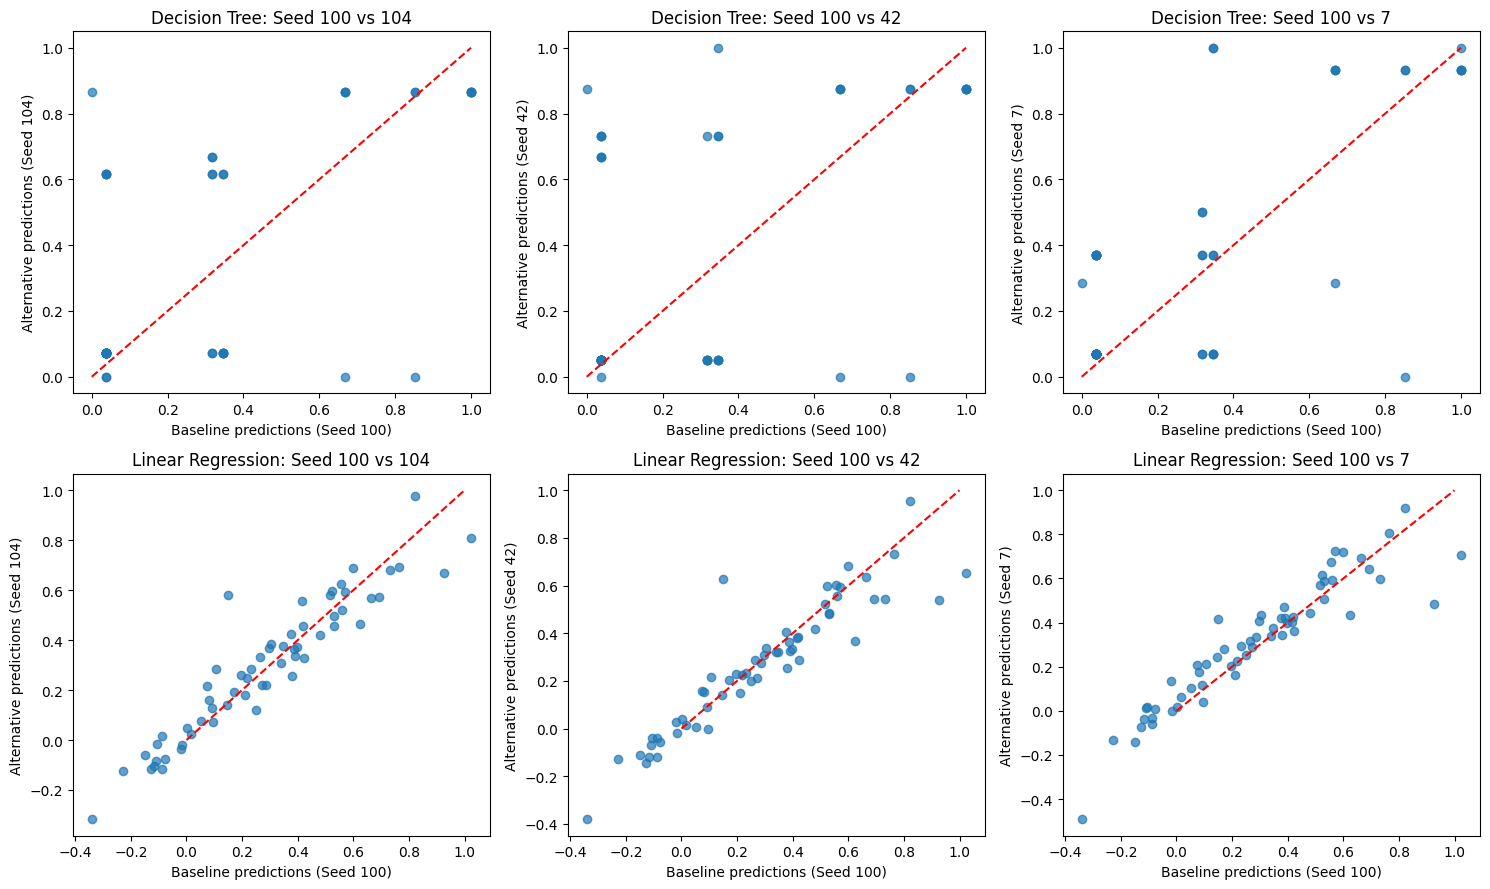

In [13]:
# Q4a: Compare predictions from the baseline and alternative models

seeds = [104, 42, 7]

tree_predictions = {
    104: y_hat_tree_104,
    42: y_hat_tree_42,
    7: y_hat_tree_7
}

linear_predictions = {
    104: y_hat_lin_104,
    42: y_hat_lin_42,
    7: y_hat_lin_7
}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for i, seed in enumerate(seeds):
    # Decision tree predictions
    axes[0, i].scatter(y_hat_tree, tree_predictions[seed], alpha=0.7)
    axes[0, i].plot([0, 1], [0, 1], 'r--')
    axes[0, i].set_title(f"Decision Tree: Seed 100 vs {seed}")
    axes[0, i].set_xlabel("Baseline predictions (Seed 100)")
    axes[0, i].set_ylabel(f"Alternative predictions (Seed {seed})")

    # Linear regression predictions
    axes[1, i].scatter(y_hat_linear, linear_predictions[seed], alpha=0.7)
    axes[1, i].plot([0, 1], [0, 1], 'r--')
    axes[1, i].set_title(f"Linear Regression: Seed 100 vs {seed}")
    axes[1, i].set_xlabel("Baseline predictions (Seed 100)")
    axes[1, i].set_ylabel(f"Alternative predictions (Seed {seed})")

plt.tight_layout()
plt.show()

The scatterplots show that the linear regression models have more similar predictions across the different seeds. Most of their points are close to the diagonal line. This means that  the predictions are fairly consistent. The decision trees show more variation. And with several points farther away from the diagonal, it suggests that decision trees are more sensitive to changes in the training data, while linear regression models are more stable.

### Q4b: Correlations Between Model Predictions

Calculate the correlation between the predictions from the Question 2 baseline models and each alternative model from Question 3.

Calculate the correlations separately for decision trees and linear regression models.

Explain whether the predictions are highly correlated.

In [14]:
# Q4b: Pearson correlations between baseline and alternative predictions

correlation_results = []

for seed in seeds:
    tree_corr = np.corrcoef(
        y_hat_tree, tree_predictions[seed]
    )[0, 1]

    linear_corr = np.corrcoef(
        y_hat_linear, linear_predictions[seed]
    )[0, 1]

    correlation_results.append({
        "Alternative Seed": seed,
        "Tree Correlation": tree_corr,
        "Linear Correlation": linear_corr
    })

correlation_df = pd.DataFrame(correlation_results)
display(correlation_df.round(4))

,Alternative Seed,Tree Correlation,Linear Correlation
0,104,0.6585,0.9413
1,42,0.5719,0.9237
2,7,0.7680,0.9337


The linear models have high correlations (0.9237–0.9413), showing their predictions are very similar across seeds. The decision trees have lower correlations (0.5719–0.7680), meaning their predictions vary more. Overall, linear regression is more stable across the different training splits.

### Q4c: Linear Regression Comparisons

Run a simple linear regression using the predictions from Question 2 as the independent variable and the predictions from each alternative model in Question 3 as the dependent variable.

Perform this analysis separately for decision trees and linear regression models.

For each comparison, report the intercept, slope, and R².

Explain whether the intercept is close to zero, the slope is close to one, and R² is close to one.

In [15]:
# Q4c: Regress alternative model predictions on baseline predictions

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

regression_results = []

for seed in seeds:

    # Decision tree comparison
    tree_reg = LinearRegression().fit(
        y_hat_tree.reshape(-1, 1),
        tree_predictions[seed]
    )

    tree_r2 = tree_reg.score(
        y_hat_tree.reshape(-1, 1),
        tree_predictions[seed]
    )

    regression_results.append({
        "Model": "Decision Tree",
        "Alternative Seed": seed,
        "Intercept": tree_reg.intercept_,
        "Slope": tree_reg.coef_[0],
        "R-squared": tree_r2
    })

    # Linear regression comparison
    linear_reg = LinearRegression().fit(
        y_hat_linear.reshape(-1, 1),
        linear_predictions[seed]
    )

    linear_r2 = linear_reg.score(
        y_hat_linear.reshape(-1, 1),
        linear_predictions[seed]
    )

    regression_results.append({
        "Model": "Linear Regression",
        "Alternative Seed": seed,
        "Intercept": linear_reg.intercept_,
        "Slope": linear_reg.coef_[0],
        "R-squared": linear_r2
    })

regression_df = pd.DataFrame(regression_results)
display(regression_df.round(4))

,Model,Alternative Seed,Intercept,Slope,R-squared
0,Decision Tree,104,0.1236,0.6856,0.4336
1,Linear Regression,104,0.0509,0.8588,0.8861
2,Decision Tree,42,0.1416,0.6528,0.3270
3,Linear Regression,42,0.0363,0.8241,0.8532
4,Decision Tree,7,0.1063,0.8119,0.5899
5,Linear Regression,7,0.0694,0.8529,0.8717


question 5:

The linear regression models were fairly consistent across the four different data splits. Most variables kept the same positive or negative relationship with the outcome, although some coefficients changed slightly depending on the training data. Their predictions were also very similar, with correlations between 0.9237 and 0.9413. This indicates that linear regression was relatively stable even when the data was split differently.

The decision trees showed more changes across the different data splits. Their structures and splitting points varied depending on which observations were used for training. Their prediction correlations were also lower, ranging from 0.5719 to 0.7680. This suggests that decision trees are more sensitive to changes in the training data compared to linear regression.

Question 6:
True

Models can have very different structures but still produce similar predictions. Our results showed this with the linear regression models, which maintained highly correlated predictions despite some differences in their coefficients. The decision trees showed more variation, but their predictions still had some similarities. Overall, this shows that models do not necessarily need to look alike to produce similar results.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]